# Weighted Coverage Exponential vs Lawnmower

Here, we weight some of the regions to have higher importance as compared to others based on the rated value. The objective is also computed based on the weights 

In [1]:
import Pkg; Pkg.activate("../.."); Pkg.instantiate()

  Activating project at `~/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim`


In [2]:
using Logging: global_logger
using TerminalLoggers: TerminalLogger
global_logger(TerminalLogger())

using ProgressLogging

In [3]:
using Plots, Revise, StaticArrays, Interpolations, LinearAlgebra

In [4]:
include("../../src/kf.jl")
include("../../src/ngpkf.jl")
include("../../src/SyntheticData.jl")
include("../../src/ergodic.jl")
include("../../src/simulator_spatial.jl")
include("../../src/TrajLib.jl")

Main.TrajectoryLibrary

## Spatial-only Matern-12 Kernel

In [5]:
# Define domain vars
dim = 100; # number of data points along each axis in the domain (defining a square domain)
xstart, xstop = 0, 25; # x-axis start and end positions
ystart, ystop = 0, 10; # y-axis start and end positions

σ_sq = 1.0
λₓ = 1/(5.0) 

env_data = SyntheticData.matern12_spatial(dim, xstart, xstop, ystart, ystop, σ_sq, λₓ);
# heatmap(range(xstart, stop=xstop, length=dim), range(ystart, stop=ystop, length=dim), env_data; c = :vik)
# title!("Synthetic Data: σ² = $(σ_sq), λₓ = $(λₓ)")

In [6]:
plotly();
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
# plot!(clims=(-2,2))

┌ Warning: Failed to load integration with PlotlyBase & PlotlyKaleido.
│   exception =
│    ArgumentError: Package PlotlyBase not found in current path.
│    - Run `import Pkg; Pkg.add("PlotlyBase")` to install the PlotlyBase package.
│    Stacktrace:
│      [1] macro expansion
│        @ Base ./loading.jl:1766 [inlined]
│      [2] macro expansion
│        @ Base ./lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base ./loading.jl:1747
│      [4] #invoke_in_world#3
│        @ Base ./essentials.jl:921 [inlined]
│      [5] invoke_in_world
│        @ Base ./essentials.jl:918 [inlined]
│      [6] require(into::Module, mod::Symbol)
│        @ Base ./loading.jl:1740
│      [7] top-level scope
│        @ ~/.julia/packages/Plots/ju9dp/src/backends.jl:565
│      [8] eval
│        @ ./boot.jl:385 [inlined]
│      [9] _initialize_backend(pkg::Plots.PlotlyBackend)
│        @ Plots ~/.julia/packages/Plots/ju9dp/src/backends.jl:564
│     [10] backend
│        @ Plots 

In [7]:
# Create an ngpkf grid based on the data

σ_spatial = σ_sq
# l_spatial = 1/λₓ_wrong
l_spatial = 1/λₓ

res_factor = 0.4 #l_spatial / sqrt(2.0)

kern = NGPKF.MaternKernel(σ_spatial, l_spatial)

ngp_grid_x = range(extrema(env_data.X)..., step= res_factor )
ngp_grid_y = range(extrema(env_data.Y)..., step= res_factor )


0.0:0.4:10.0

In [8]:
kern

Main.NGPKF.MaternKernel{Float64}(1.0, 5.0)

In [9]:
ngpkf_grid = NGPKF.NGPKFGrid(ngp_grid_x, ngp_grid_y, kern)

Main.NGPKF.NGPKFGrid{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{SVector{2, Float64}}, Hermitian{Float64, Matrix{Float64}}, Main.NGPKF.MaternKernel{Float64}}(0.0:0.4:24.8, 0.0:0.4:10.0, SVector{2, Float64}[[0.0, 0.0], [0.4, 0.0], [0.8, 0.0], [1.2, 0.0], [1.6, 0.0], [2.0, 0.0], [2.4, 0.0], [2.8, 0.0], [3.2, 0.0], [3.6, 0.0]  …  [21.2, 10.0], [21.6, 10.0], [22.0, 10.0], [22.4, 10.0], [22.8, 10.0], [23.2, 10.0], [23.6, 10.0], [24.0, 10.0], [24.4, 10.0], [24.8, 10.0]], Main.NGPKF.MaternKernel{Float64}(1.0, 5.0), [10.221468408218861 -5.359611588172402 … 8.996671573591833e-7 3.2167883955530496e-6; -5.359611588172402 14.078370726036614 … 1.9874550557233728e-7 8.996671571317452e-7; … ; 8.996671573591833e-7 1.9874550557233728e-7 … 14.078370726036683 -5.359611588172417; 3.2167883955530496e-6 8.996671571317452e-7 … -5.359611588172417 10.22146840821888])

In [10]:
size(ngp_grid_x), size(ngp_grid_y)

((63,), (26,))

In [11]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]


1-element Vector{SVector{2, Float64}}:
 [20.8, 7.6]

In [12]:
SimulatorSpatial.measure(0.0, x0s, env_data; σ_meas = 0.05)

1-element Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}:
 Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}(0.0, [20.8, 7.6], -0.3253455597948839)

In [13]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
scatter!(first.(x0s), last.(x0s), label = "")
title!("q_T= 0.95 for w_T = 1.5 | Rest = 0.0")
# plot!(clims=(-2,2))

In [14]:
function Cfun(p, x)
    return kern(x, p)^2 / kern(p, p)
end
function Rfun(p, x)
    return (kern(x,x) - kern(x, p)^2 / kern(p, p) + 0.5^2)/(ΔT)
end


S(p, x)  = Cfun(p, x)^2 / Rfun(p, x)
DxS(p, x) = ForwardDiff.gradient(xx-> S(p, xx), x)

DxS (generic function with 1 method)

In [15]:
using DifferentialEquations
using ForwardDiff

# function clarity_prediction(t, q0, C, R, Q)

#     k = C / sqrt(Q * R)
    
#     q∞ = k / (1 + k)

#     γ1 = q∞ - q0
#     γ2 = γ1 * (k-1)
#     γ3 = (k-1) * q0 - k

#     return q∞ * ( 1 + 2 * γ1 / (γ2 + γ3 * exp(2 * k * Q * t)))
# end

    
# function clarity_time(q0, qf, C, R, Q; tmax=10.0)
    
#     println("q0: $(q0)")
#     println("qf: $(qf)")
#     println("C: $(C)")
#     println("R: $(R)")
#     println("Q: $(Q)")
    
#     if q0 >= qf
#         return 0.0
#     end

#     k = C / sqrt(Q * R)
#     println("k: $(k)")
    
#     q∞ = k / (1 + k)
#     println("q∞: $(q∞)")
#     γ1 = q∞ - q0
#     γ2 = γ1 * (k-1)
#     γ3 = (k-1) * q0 - k

    
        
#     if qf >= q∞
#         return tmax
#     end

#     t = log((2*q∞*γ1 - qf*γ2 + q∞*γ2)/((qf - q∞)*γ3))/(2*k*Q)
#     println("t: $(t)")

#     return min(t, tmax)
# end


C_ = Cfun(0,0)
R_ = Rfun(0,0)

k = (C_^2 / R_)
# q(t) = ((-k * t * q_0) + (k * t * q_0)) / ((-k * t * q_0) + (k * t) + 1)

function Clarity_delta_t(current_clarity, target_clarity)
    delta_t = (target_clarity - current_clarity) / ((target_clarity - 1) * k * (current_clarity - 1))
    return delta_t
end

function Clarity_delta_new(current_clarity, target_clarity)
    den = -target_clarity*k + k*current_clarity*target_clarity + k - k*current_clarity
    return delta_t = (target_clarity - current_clarity) / den
end


LoadError: UndefVarError: `ΔT` not defined

In [16]:
# Controller for weighted 2
using LinearAlgebra, StatsBase

function ergo_controller_weighted_2(t, xs, Mean, w_rated_val;
        ergo_grid,
        ergo_q_map,
        traj,
        umax=30.0 * 60 / 1000,
        ΔT,
        kwargs...
        )
        
    target_q = 0.95

    # Set the rated value matrix    
    Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
    w_rated = ones(Nx, Ny)
    w_rated *= w_rated_val
  
#   Compute the target matrix 
    lambda_param = 0.1
    delta = -lambda_param*((Mean - w_rated).^2)
    q_target_temp = target_q*(exp.(delta))    

    # Get it in the right shape
    q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Line())
    q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid))     

    
    target_spatial_dist = zeros(size(ergo_q_map))
    Qp  = mean(σ_t.^2) # diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT ))      
    
    for i in CartesianIndices(target_spatial_dist)
        if q_target_weighted[i] > ergo_q_map[i]
#             println("here in first cond")
            target_spatial_dist[i] = Clarity_delta_new(ergo_q_map[i], q_target_weighted[i])
        else
            target_spatial_dist[i] = 0.0
        end
    end
        
    u = [ErgodicController.controller_single_integrator(ergo_grid, x, traj, target_spatial_dist; umax=umax) for x in xs]
    
#     println(u)
    
    return u, q_target_temp

end

ergo_controllers_weighted_2 = [ergo_controller_weighted_2 for i=1:length(x0s)]

1-element Vector{typeof(ergo_controller_weighted_2)}:
 ergo_controller_weighted_2 (generic function with 1 method)

In [17]:
# Frequencies
# Control input: Every 5 seconds
# Fusing Measurements: Every 300 seconds

ΔT = 5.0/60.0 # minutes
Tend = 0.1 # hours 
ts = 0.0:(ΔT):(300)
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes i.e. every 5 seconds 
σ_t = zeros(63, 26);

In [26]:
ergo_grid = SimulatorSpatial.ErgoGrid(ngpkf_grid, (256, 256))
lower = ergo_grid.o
upper = ergo_grid.o + @SVector [ (ergo_grid.N[i]-1) * ergo_grid.dx[i] for i=1:2]

2-element SVector{2, Float64} with indices SOneTo(2):
 24.8
 10.0

In [53]:
x0s = [@SVector[rand(ngpkf_grid.xs[2:(end-2)]), rand(ngpkf_grid.ys[2:(end-2)])] for i=1:1]


1-element Vector{SVector{2, Float64}}:
 [20.4, 2.4]

In [81]:
x0ss = [@SVector[25., 2]]

1-element Vector{SVector{2, Float64}}:
 [25.0, 2.0]

In [82]:
α = 1
p = x0ss


1-element Vector{SVector{2, Float64}}:
 [25.0, 2.0]

In [83]:
h1 = p[1][1] - lower[1]
@show h1
ux_min = -α * h1

h1 = 25.0


-25.0

In [84]:
h2 = upper[1] - p[1][1]
ux_max = α * h2

-0.1999999999999993

In [85]:
h3 = p[1][2] - lower[2]
uy_min = -α * h3

-2.0

In [86]:
h4 = upper[2] - p[1][2]
uy_max = α * h4

8.0

In [79]:
u1 = -1.5
u2 = 1.5
ux = clamp(u1, ux_min, ux_max)
uy = clamp(u2, uy_min, uy_max)
@show ux
@show uy

ux = -0.0
uy = 1.5


1.5

In [80]:
w_rated_val = 1.5
@time res_ergo_exp =  SimulatorSpatial.simulate_weighted_exp_spatial(ts, x0s, ergo_controller_weighted_2, w_rated_val; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:01:07
Progress:   1%|▍                                        |  ETA: 0:01:06


Inside prediction of NGP


Progress:   2%|▋                                        |  ETA: 0:01:05
Progress:   2%|▉                                        |  ETA: 0:01:34
Progress:   3%|█▏                                       |  ETA: 0:01:29
Progress:   3%|█▎                                       |  ETA: 0:01:24


Inside prediction of NGP


Progress:   4%|█▌                                       |  ETA: 0:01:38
Progress:   4%|█▊                                       |  ETA: 0:01:33
Progress:   5%|█▉                                       |  ETA: 0:01:29


...

Inside prediction of NGP


Progress:  98%|████████████████████████████████████████▍|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:01
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:01


 86.331092 seconds (2.47 G allocations: 75.555 GiB, 23.61% gc time)


Progress: 100%|█████████████████████████████████████████|  ETA: 0:00:00
Progress: 100%|█████████████████████████████████████████| Time: 0:01:26


Main.SimulatorSpatial.SimResultWeighted{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:300.0, Vector{SVector{2, Float64}}[[[3.2, 4.8]], [[3.340282925865516, 4.8531102693517]], [[3.457282338092698, 4.946977929056701]], [[3.5848761224030095, 5.025843803840246]], [[3.7152149774390324, 5.100085186288976]], [[3.841171331202182, 5.181540676875507]], [[3.9663016525584114, 5.264259493823567]], [[4.091508912987235, 5.346861805751918]], [[4.2103791380679345, 5.438348797118253]], [[4.3262674350678045, 5.533584833462012]]  …  [[12.54827233510673, 1.077839809630207]], [[12.434719997491914, 1.1758493327502126]], [[12.551339637096845, 1.0815102652414

In [81]:
res_ergo_exp.ts

0.0:0.08333333333333333:300.0

## RMSE and Precision

In [82]:
# rmse and precision 

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M = reshape(KF.μ(res_ergo_exp.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M' .- Data_sampled
@show normal_rmse = sqrt(mean(Diff .^ 2))
    
# Compute the weights 
# Set the rated value matrix    
Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
w_rated = ones(Nx, Ny)
w_rated *= w_rated_val

lambda_param_obj = 0.1
d_weight = -lambda_param_obj*((Data_sampled' - w_rated).^2)
weight_matrix = exp.(d_weight)

weighted_diff = (Diff .^ 2) .* weight_matrix' 
@show weighted_rmse = sqrt(mean(weighted_diff))
    
heatmap(weight_matrix')

normal_rmse = sqrt(mean(Diff .^ 2)) = 0.31597600107056784
weighted_rmse = sqrt(mean(weighted_diff)) = 0.23380529312809892


In [83]:
# Compute Precision

σ_prec = KF.σ(res_ergo_exp.w_hats[end])
M_prec = reshape(σ_prec, Nx, Ny)
weighted_M_prec = reshape(σ_prec, Nx, Ny) .* weight_matrix
@show normal_precision = sum(M_prec)/length(M_prec)
@show weighted_precision = sum(weighted_M_prec)/length(weighted_M_prec);

normal_precision = sum(M_prec) / length(M_prec) = 0.36111926482023093
weighted_precision = sum(weighted_M_prec) / length(weighted_M_prec) = 0.2505253801872108


In [84]:
# Compute Clarity Deficit
using LinearAlgebra, StatsBase

mean_deficit_ergo = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_ergo_exp.ergo_q_maps]

60-element Vector{Float64}:
 0.499999999999997
 0.41767494958339535
 0.3630630162686998
 0.3329586759926322
 0.30832160140669357
 0.2947512446863781
 0.2821849118901447
 0.27386992857297565
 0.25093895651826026
 0.20528939830546633
 0.1861640383602352
 0.17888463925885673
 0.17484458952203763
 ⋮
 0.12799165582345629
 0.12766593181506802
 0.12593244548012827
 0.12541243172727845
 0.12507840520941282
 0.12435642122486822
 0.1241054547529275
 0.12362215961369077
 0.12333018194419278
 0.12318078107600185
 0.12295807582135539
 0.12272187811705473

## Plots 


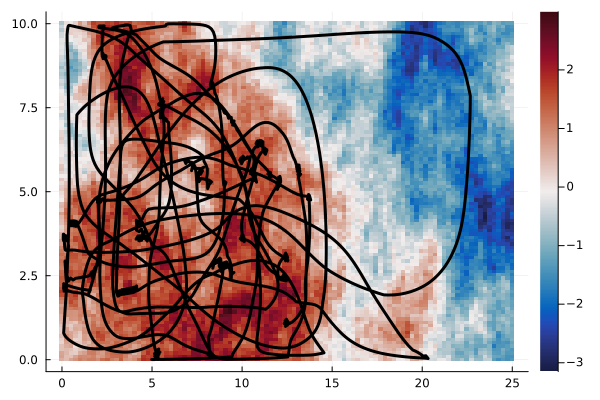

In [200]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
for i=1:length(x0s)
    x = [r[i][1] for r in res_ergo_exp.xs]
    y = [r[i][2] for r in res_ergo_exp.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

# title!("q_T= 0.95 for exponential weighted coverage")

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
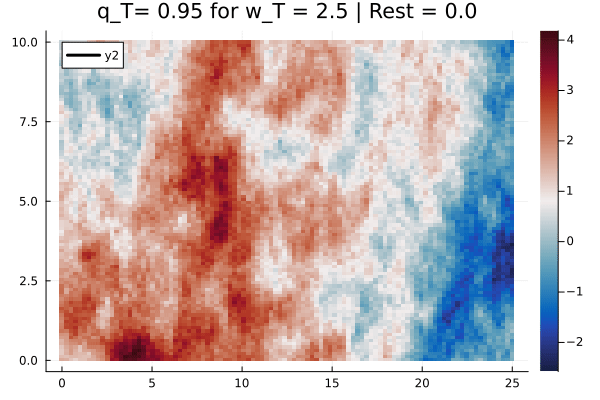

In [32]:
gr()
@gif for n = Int.(floor.(range(1, length(res_ergo_exp.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
    for i=1:length(x0s)
        x = [r[i][1] for r in res_ergo_exp.xs[1:n]]
        y = [r[i][2] for r in res_ergo_exp.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

In [86]:
p2 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

In [89]:
length(res_ergo_exp.q_target_maps)

3601

In [91]:
length(res_ergo_exp.ergo_q_maps)

60

In [92]:
target_maps_exp = [res_ergo_exp.q_target_maps[1],]

for i=2:62:length(res_ergo_exp.q_target_maps)
    push!(target_maps_exp,res_ergo_exp.q_target_maps[i])
end

In [93]:
length(target_maps_exp)

60

In [37]:
# gr()
# @gif for i=1:length(res_ergo_exp.q_target_maps)
#     heatmap(res_ergo_exp.q_target_maps[i]', clims=(0, 1))
#     title!("Target clarity map over time: iteration $i")
# end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
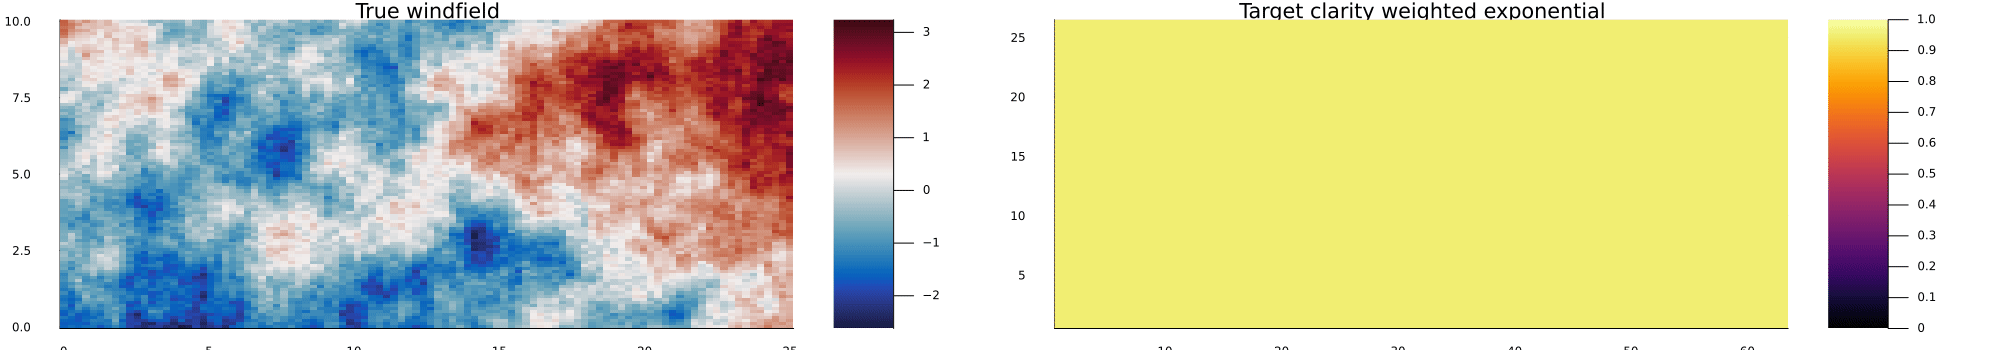

In [46]:
# # Comparing two target clarities
# gr()
# @gif for i=1:length(res_ergo_exp.q_target_maps)
#     p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
#     p1 = heatmap(res_ergo_exp.q_target_maps[i]', clims=(0, 1), title = "Target clarity weighted exponential")
#     plot(p0, p1, layout=@layout[a b], size=(2000, 350))
# #     title!("Weighted coverage")
# end

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
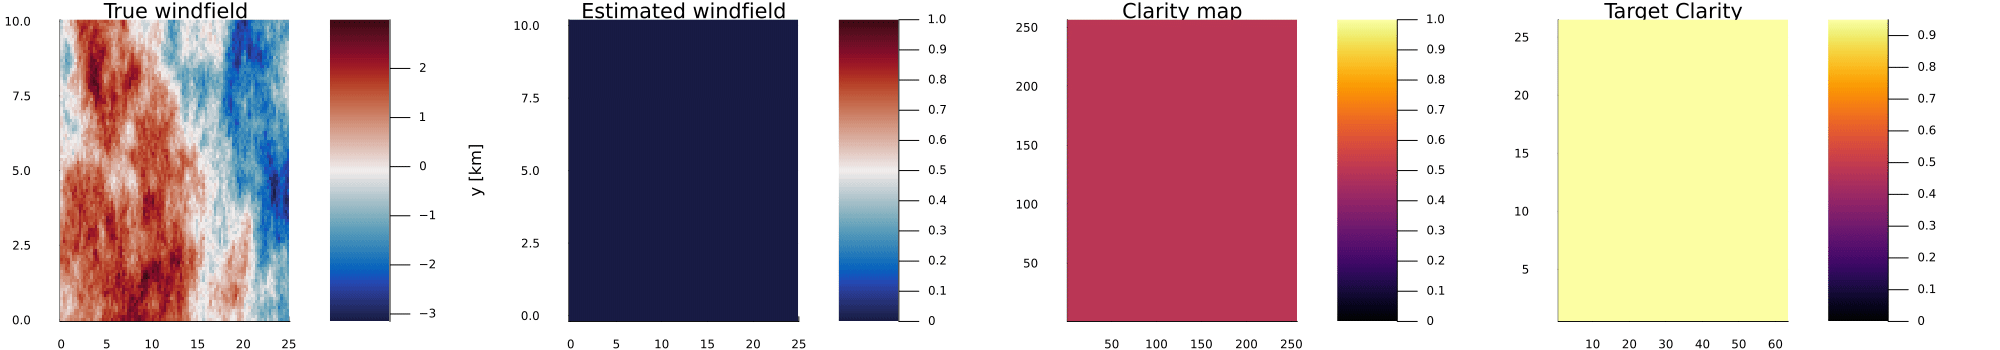

In [94]:
gr()
@gif for i=1:length(res_ergo_exp.ergo_q_maps)
    p0 = heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx, title = "True windfield")
    p1 = heatmap(ngpkf_grid, res_ergo_exp.w_hats[i],colormap=:balance, title = "Estimated windfield")
    p3 = heatmap(target_maps_exp[i]', title = "Target Clarity")
    p2 = heatmap(res_ergo_exp.ergo_q_maps[i]', clims=(0, 1), title = "Clarity map")
    plot(p0, p1, p2, p3, layout=@layout[a b c d], size=(2000, 350))
#     title!("Weighted coverage")
end

## Lawnmower

In [201]:
# Define lawn dimensions (length and width) in km
lawn_length = 25.0
lawn_width = 10.0

# Define the top speed of the robot in km/minute
top_speed = 1.8

# Define the sampling interval in minutes
sampling_interval = 5.0 / 60.0

# Define the total number of points
total_points = 2000

# Define a fixed mowing width in km
mowing_width = 5.0

lawn_traj =  TrajectoryLibrary.generate_smooth_lawnmower_path(lawn_length, lawn_width, mowing_width, top_speed,sampling_interval, total_points);
@show size(lawn_traj,1)

size(lawn_traj, 1) = 836


836

In [202]:
1504 * 5.0 / 60.0

125.33333333333333

In [203]:
reverse_lawn_traj = reverse(lawn_traj);

In [204]:
time_lawn = size(lawn_traj, 1) * 5.0 / 60.0

69.66666666666667

In [205]:
836*2 * 5.0 / 60.0

139.33333333333334

In [206]:
lawn_traj_300 = [lawn_traj; reverse_lawn_traj; lawn_traj; reverse_lawn_traj; lawn_traj]

4180-element Vector{Vector{SVector{2, Float64}}}:
 [[0.0, 0.0]]
 [[0.1497005988023952, 0.0]]
 [[0.2994011976047904, 0.0]]
 [[0.4491017964071856, 0.0]]
 [[0.5988023952095808, 0.0]]
 [[0.7485029940119761, 0.0]]
 [[0.8982035928143712, 0.0]]
 [[1.0479041916167664, 0.0]]
 [[1.1976047904191616, 0.0]]
 [[1.347305389221557, 0.0]]
 [[1.4970059880239521, 0.0]]
 [[1.6467065868263473, 0.0]]
 [[1.7964071856287425, 0.0]]
 ⋮
 [[23.353293413173652, 10.0]]
 [[23.50299401197605, 10.0]]
 [[23.652694610778443, 10.0]]
 [[23.802395209580837, 10.0]]
 [[23.952095808383234, 10.0]]
 [[24.101796407185628, 10.0]]
 [[24.251497005988025, 10.0]]
 [[24.40119760479042, 10.0]]
 [[24.550898203592816, 10.0]]
 [[24.70059880239521, 10.0]]
 [[24.850299401197606, 10.0]]
 [[25.0, 10.0]]

In [136]:
# gr()
# @gif for n = Int.(floor.(range(1, length(lawn_traj), length=420)))
#     plot()
#     heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
#     for i=1:length(x0s)
#         x = [r[i][1] for r in lawn_traj_120[1:n]]
#         y = [r[i][2] for r in lawn_traj_120[1:n]]
#         plot!(x, y, linewidth=3, color=:black)
#     end
#     plot!()
# end

In [137]:
# # Lawnmower trajectory in reverse
# gr()
# @gif for n = Int.(floor.(range(1, length(lawn_traj), length=420)))
#     plot()
#     heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
#     for i=1:length(x0s)
#         x = [r[i][1] for r in reverse_lawn_traj[1:n]]
#         y = [r[i][2] for r in reverse_lawn_traj[1:n]]
#         plot!(x, y, linewidth=3, color=:black)
#     end
#     plot!()
# end

In [138]:
# plot()
# heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
# for i=1:1
#     x = [r[i][1] for r in lawn_traj_120]
#     y = [r[i][2] for r in lawn_traj_120]
#     plot!(x, y, linewidth=3, color=:black)
# end
# plot!()

In [139]:
# x = [r[1][1] for r in lawn_traj]
# y = [r[1][2] for r in lawn_traj]
# plot(x, y)

In [261]:
ΔT = 5.0/60.0 # minutes
Tend = 0.1 # hours 
ts = 0.0:(ΔT):(180)
fuse_measurements_every_ΔT = 5.0 # minutes
recompute_controller_every_ΔT = 5.0 / 60.0 # minutes i.e. every 5 seconds 
σ_t = zeros(63, 26);

In [262]:
@time res_lawn =  SimulatorSpatial.simulate_prerec_traj(ts, lawn_traj_300; 
    ngpkf_grid=ngpkf_grid, 
    EnvDataSpatial=env_data, 
    σ_meas = 0.5,
    # σ_process= 0.075 * fuse_measurements_every_ΔT,
    Q_process = diagm(vec(σ_t .^2 * fuse_measurements_every_ΔT )) , 
    fuse_measurements_every_ΔT = fuse_measurements_every_ΔT, 
    recompute_controller_every_ΔT = recompute_controller_every_ΔT)

Inside prediction of NGP


Progress:   0%|                                         |  ETA: N/A
Progress:   1%|▎                                        |  ETA: 0:00:00
Progress:   1%|▍                                        |  ETA: 0:00:00
Progress:   2%|▋                                        |  ETA: 0:00:00
Progress:   2%|▉                                        |  ETA: 0:00:00
Progress:   3%|█                                        |  ETA: 0:00:00


Inside prediction of NGP


Progress:   3%|█▎                                       |  ETA: 0:00:11
Progress:   4%|█▌                                       |  ETA: 0:00:09
Progress:   4%|█▋                                       |  ETA: 0:00:08
Progress:   5%|█▉                                       |  ETA: 0:00:07
Progress:   5%|██▏                                      |  ETA: 0:00:06


Inside prediction of NGP


...

Inside prediction of NGP


Progress:  95%|██████████████████████████████████████▉  |  ETA: 0:00:01
Progress:  95%|███████████████████████████████████████  |  ETA: 0:00:01
Progress:  96%|███████████████████████████████████████▎ |  ETA: 0:00:01
Progress:  96%|███████████████████████████████████████▌ |  ETA: 0:00:01
Progress:  97%|███████████████████████████████████████▋ |  ETA: 0:00:01


 19.383618 seconds (46.84 k allocations: 7.427 GiB, 41.40% gc time)


Progress:  97%|███████████████████████████████████████▉ |  ETA: 0:00:01
Progress:  98%|████████████████████████████████████████▏|  ETA: 0:00:00
Progress:  98%|████████████████████████████████████████▎|  ETA: 0:00:00
Progress:  99%|████████████████████████████████████████▌|  ETA: 0:00:00
Progress:  99%|████████████████████████████████████████▊|  ETA: 0:00:00
Progress: 100%|████████████████████████████████████████▉|  ETA: 0:00:00
Progress: 100%|█████████████████████████████████████████| Time: 0:00:19


Main.SimulatorSpatial.SimResultPre{StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}, Vector{Vector{SVector{2, Float64}}}, Vector{Main.SimulatorSpatial.MeasurementSpatial{Float64, SVector{2, Float64}, Float64}}, Vector{Float64}, Vector{Main.KF.KFState{Vector{Float64}, UpperTriangular{Float64, Matrix{Float64}}}}, Vector{Matrix{Float64}}}(0.0:0.08333333333333333:180.0, Vector{SVector{2, Float64}}[[[0.0, 0.0]], [[0.1497005988023952, 0.0]], [[0.2994011976047904, 0.0]], [[0.4491017964071856, 0.0]], [[0.5988023952095808, 0.0]], [[0.7485029940119761, 0.0]], [[0.8982035928143712, 0.0]], [[1.0479041916167664, 0.0]], [[1.1976047904191616, 0.0]], [[1.347305389221557, 0.0]]  …  [[3.2934131736526946, 5.0]], [[3.143712574850299, 5.0]], [[2.9940119760479043, 5.0]], [[2.844311377245509, 5.0]], [[2.694610778443114, 5.0]], [[2.5449101796407185, 5.0]], [[2.395209580838323, 5.0]], [[2.245508982035928, 5.0]], [[2.095808383233533, 5.0]], [[1.9461077844311376, 5.0]]], M

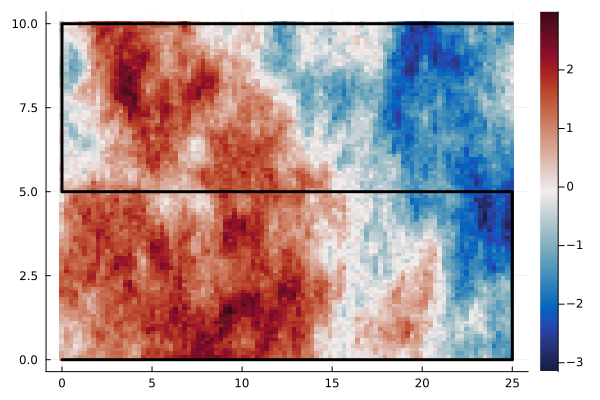

In [263]:
plot()
heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
for i=1:length(x0s)
    x = [r[i][1] for r in res_lawn.xs]
    y = [r[i][2] for r in res_lawn.xs]
    plot!(x,y, linewidth=3, color=:black, label = "")
end
plot!()

┌ Info: Saved animation to
└ /home/dasc-group/KalebData/PhDResearch/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif


Plots.AnimatedGif("/home/dasc-group/Kaleb_Data/PhD_Research/CPS_Project/adaptive-ocean-exploration-sim/tmp.gif")
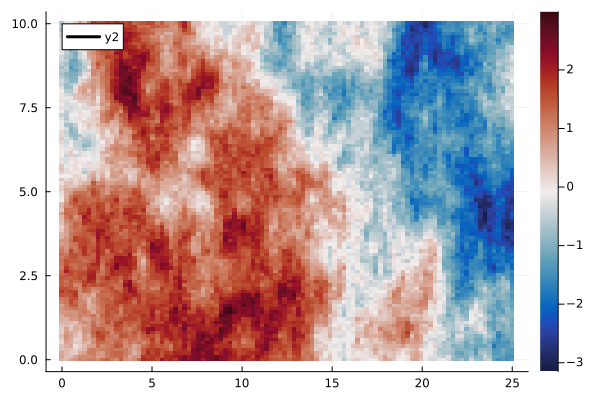

In [264]:
gr()
@gif for n = Int.(floor.(range(1, length(res_lawn.xs), length=420)))
    plot()
    heatmap(env_data.X, env_data.Y, env_data.W', cmap = :balance; plottype=:wx)
    for i=1:length(x0s)
        x = [r[i][1] for r in res_lawn.xs[1:n]]
        y = [r[i][2] for r in res_lawn.xs[1:n]]
        plot!(x, y, linewidth=3, color=:black)
    end
    plot!()
end

normal_rmse = sqrt(mean(Diff .^ 2)) = 0.47967895547446654
weighted_rmse = sqrt(mean(weighted_diff)) = 0.4233603843691309


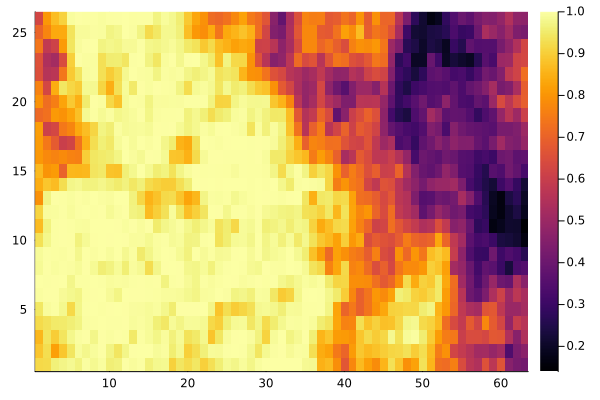

In [265]:
# rmse and precision 

Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)

M_l = reshape(KF.μ(res_lawn.w_hats[end]), Nx, Ny)
heatmap(M',colormap=:balance, clims=(-2,2) )
x_new = 0:0.4:25
y_new = 0:0.4:10
Data_sampled = [env_data.itp_w(xi, yi) for yi in y_new, xi in x_new]
Diff = M_l' .- Data_sampled
@show normal_rmse = sqrt(mean(Diff .^ 2))
    
# Compute the weights 
# Set the rated value matrix    
Nx, Ny = length(ngpkf_grid.xs), length(ngpkf_grid.ys)
w_rated = ones(Nx, Ny)
w_rated *= w_rated_val

lambda_param_obj = 0.1
d_weight = -lambda_param_obj*((Data_sampled' - w_rated).^2)
weight_matrix = exp.(d_weight)

weighted_diff = (Diff .^ 2) .* weight_matrix' 
@show weighted_rmse = sqrt(mean(weighted_diff))
    
heatmap(weight_matrix')

In [266]:
# Compute Precision

σ_prec_l = KF.σ(res_lawn.w_hats[end])
M_prec_l = reshape(σ_prec_l, Nx, Ny)
weighted_M_prec_l = reshape(σ_prec_l, Nx, Ny) .* weight_matrix
@show normal_precision = sum(M_prec_l)/length(M_prec_l)
@show weighted_precision = sum(weighted_M_prec_l)/length(weighted_M_prec_l);

normal_precision = sum(M_prec_l) / length(M_prec_l) = 0.48250313762167907
weighted_precision = sum(weighted_M_prec_l) / length(weighted_M_prec_l) = 0.3774528508183502


In [267]:
mean_deficit_lawn = [mean(map( c -> max(0, 1.0 - c), q )) for q in res_lawn.ergo_q_maps]

36-element Vector{Float64}:
 0.499999999999997
 0.45440774168056886
 0.41953668815613776
 0.40124223918349783
 0.39650006355536105
 0.3907846520207462
 0.36883965572563593
 0.32116348355962077
 0.275629272736418
 0.26464380477121463
 0.2605355147329098
 0.25806153863672643
 0.24149988180288134
 ⋮
 0.20308982563513536
 0.2030379856921139
 0.20267148720650935
 0.20225212222601954
 0.2018650870936437
 0.20169568176603428
 0.2015261391843268
 0.20142288161612365
 0.20139549356966052
 0.20136806171096833
 0.20114414360233931
 0.20076949496030327

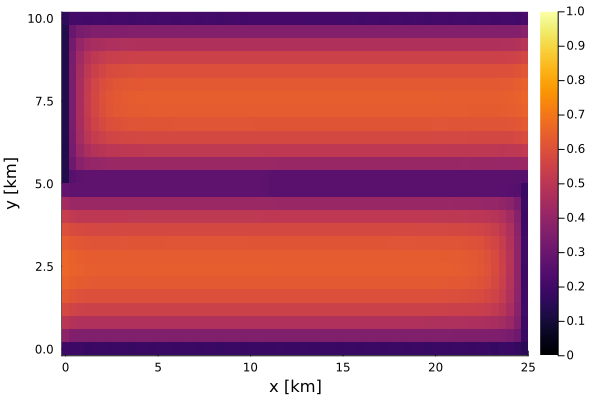

In [268]:
p2 = heatmap(ngpkf_grid, res_lawn.w_hats[end], clims=(0, 1.0), plotstd=true)
# for i=1:length(x0s)
#     x = [r[i][1] for r in res_ergo.xs]
#     y = [r[i][2] for r in res_ergo.xs]
#     plot!(x, y, linewidth=3)
# end
plot!()

In [269]:
weight_matrix

63×26 Matrix{Float64}:
 0.918116  0.88523   0.860347  0.921788  …  0.739656  0.701663  0.626101
 0.921468  0.926896  0.94019   0.935178     0.583056  0.770613  0.804129
 0.962842  0.820602  0.897995  0.949841     0.613589  0.835898  0.870312
 0.97377   0.887261  0.940138  0.95138      0.809994  0.838101  0.906503
 0.983225  0.941556  0.977102  0.959503     0.94121   0.938472  0.994303
 0.967762  0.991327  0.996071  0.970226  …  0.992562  0.990612  0.999467
 0.996187  0.977926  0.999675  0.996361     0.999694  0.99012   0.997255
 0.982356  0.991397  0.975559  0.997861     0.99988   0.996049  0.997292
 0.994164  0.99935   0.99917   0.999788     0.970054  0.994164  0.993953
 0.960046  0.971039  0.995796  0.998786     0.977252  0.970701  0.997404
 0.966037  0.942659  0.999632  0.998803  …  0.97197   0.979426  0.998732
 0.999564  0.975872  0.997572  0.999663     0.987666  0.999983  0.99981
 0.992356  0.999195  0.948989  0.991406     0.986879  0.995883  0.997151
 ⋮                           

In [270]:
# Get it in the right shape
q_target_itp = linear_interpolation((ngpkf_grid.xs, ngpkf_grid.ys), q_target_temp, extrapolation_bc=Line())
q_target_weighted = q_target_itp(ErgodicController.xs(ergo_grid), ErgodicController.ys(ergo_grid)) 

LoadError: UndefVarError: `q_target_temp` not defined

In [1]:
ergo_grid

LoadError: UndefVarError: `ergo_grid` not defined